# Vision-Based Gesture-to-Speech Translation for Sign Language

Python version: 3.12.6
Downloading dependencies.

In [2]:
%load_ext autoreload
%autoreload 2
%pip install torch
%pip install torchvision
%pip install kagglehub
%pip install opencv-python

# pytorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, datasets

# math utils
import numpy as np
import matplotlib.pyplot as plt

# kaggle (for downloading datasets) and dataset manage
import kagglehub as kh
import os

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [9]:
# dataset download
lis_path = kh.dataset_download("nicholasnisopoli/lisdataset")
asl_path = kh.dataset_download("grassknoted/asl-alphabet")
print("Italian Sing Language dataset path:", lis_path)
print("American Sign Language dataset path:", asl_path)
lis_folder = "LIS-fingerspelling-dataset"
asl_folder = "asl_alphabet_train/asl_alphabet_train" 
lis_dataset = os.path.join(lis_path, lis_folder)
asl_dataset = os.path.join(asl_path, asl_folder)

Italian Sing Language dataset path: /Users/anna/.cache/kagglehub/datasets/nicholasnisopoli/lisdataset/versions/1
American Sign Language dataset path: /Users/anna/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## Data preprocessing

In [10]:
from dataset_build import get_dataset

THRESH = 0.85
EPOCHS = 25
BATCH_SIZE = 32
LEARNING_RATE = 0.01


lis_train, lis_test = get_dataset(lis_dataset, THRESH)
lis_classes = lis_train.label_to_idx
# print(lis_test)


train_loader = DataLoader(
        lis_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
)

test_loader = DataLoader(
        lis_test,
        batch_size=BATCH_SIZE,
        shuffle=False,
)


In [11]:
print(lis_classes)

{0: 'a', 1: 'b', 2: 'c', 3: 'd', 4: 'e', 5: 'f', 6: 'h', 7: 'i', 8: 'k', 9: 'l', 10: 'm', 11: 'n', 12: 'o', 13: 'p', 14: 'q', 15: 'r', 16: 't', 17: 'u', 18: 'v', 19: 'w', 20: 'x', 21: 'y'}


In [6]:
from model import SignLanguageCNN
lis_model = SignLanguageCNN(len(classes)).to(device)

def evaluate(model, loader, criterion, device):
        model.eval()
        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        with torch.no_grad():
            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)

                logits = model(images)
                loss = criterion(logits, labels)

                total_loss += loss.item() * images.size(0)
                preds = logits.argmax(dim=1)
                total_correct += (preds == labels).sum().item()
                total_samples += images.size(0)

        avg_loss = total_loss / total_samples
        accuracy = total_correct / total_samples
        return avg_loss, accuracy

def train(model, train_loader, test_loader, epochs, lr, device):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    
    history = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": [],
    }
    
    for epoch in range(1, epochs + 1):
        model.train()

        running_loss = 0.0
        running_correct = 0
        running_samples = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            running_correct += (preds == labels).sum().item()
            running_samples += images.size(0)

        train_loss = running_loss / running_samples
        train_acc = running_correct / running_samples
        test_loss, test_acc = evaluate(model, test_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f} | "
            f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}"
        )

    return history

NameError: name 'classes' is not defined

In [ ]:
from pathlib import Path
output_dir = Path("outputs_cnn_tutorial")

history = train(
    model=lis_model,
    train_loader=train_loader,
    test_loader=test_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    device=device,
)


Epoch 01/25 | train_loss=3.3281, train_acc=0.0484 | test_loss=3.1966, test_acc=0.0461
Epoch 02/25 | train_loss=2.9686, train_acc=0.1082 | test_loss=2.8816, test_acc=0.1024
Epoch 03/25 | train_loss=2.1690, train_acc=0.2930 | test_loss=2.1546, test_acc=0.3286
Epoch 04/25 | train_loss=1.6482, train_acc=0.4566 | test_loss=1.7443, test_acc=0.4217
Epoch 05/25 | train_loss=1.3332, train_acc=0.5654 | test_loss=1.5253, test_acc=0.5067
Epoch 06/25 | train_loss=1.0831, train_acc=0.6353 | test_loss=1.1687, test_acc=0.6080
Epoch 07/25 | train_loss=0.8584, train_acc=0.7024 | test_loss=0.9491, test_acc=0.6561
Epoch 08/25 | train_loss=0.6529, train_acc=0.7711 | test_loss=0.8107, test_acc=0.7236
Epoch 09/25 | train_loss=0.4948, train_acc=0.8303 | test_loss=0.6149, test_acc=0.7984
Epoch 10/25 | train_loss=0.4065, train_acc=0.8641 | test_loss=0.6534, test_acc=0.7861
Epoch 11/25 | train_loss=0.2735, train_acc=0.9094 | test_loss=0.8862, test_acc=0.7922
Epoch 12/25 | train_loss=0.2195, train_acc=0.9246 | te

In [ ]:
torch.save(lis_model, 'lis_model.pth')

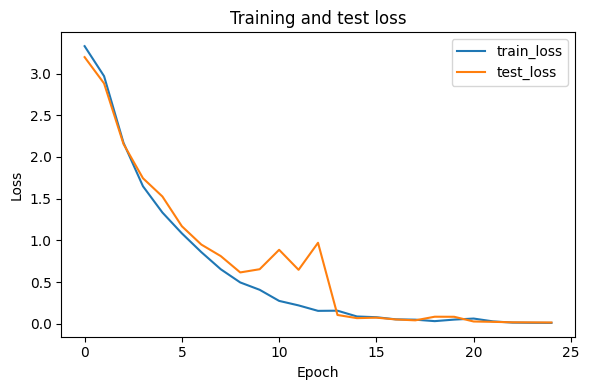

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train_loss")
plt.plot(history["test_loss"], label="test_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and test loss")
plt.legend()
plt.tight_layout()
# plt.savefig(output_dir / "03_loss_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

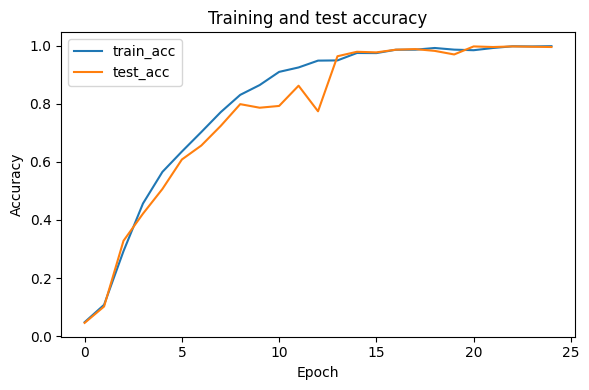

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_acc"], label="train_acc")
plt.plot(history["test_acc"], label="test_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and test accuracy")
plt.legend()
plt.tight_layout()
# plt.savefig(output_dir / "04_accuracy_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()


In [ ]:
asl_train, asl_test = get_dataset(asl_dataset, THRESH)
asl_classes = asl_train.label_to_idx
# print(lis_test)


train_loader = DataLoader(
        asl_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
)

test_loader = DataLoader(
        asl_test,
        batch_size=BATCH_SIZE,
        shuffle=False,
)


asl_model = SignLanguageCNN(len(classes)).to(device)

In [ ]:

from pathlib import Path
output_dir = Path("outputs_cnn_tutorial")

history = train(
    model=asl_model,
    train_loader=train_loader,
    test_loader=test_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    device=device,
)

Epoch 01/25 | train_loss=2.9726, train_acc=0.1438 | test_loss=2.2201, test_acc=0.2932


KeyboardInterrupt: 

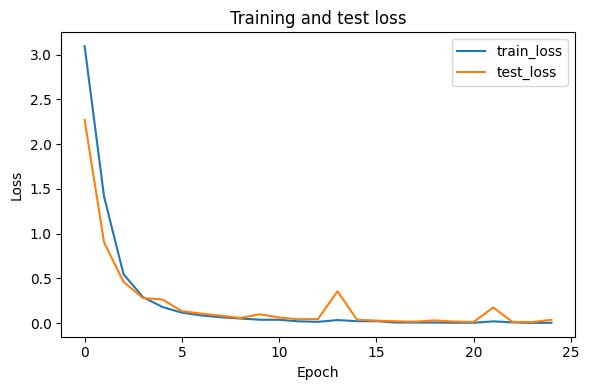

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train_loss")
plt.plot(history["test_loss"], label="test_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and test loss")
plt.legend()
plt.tight_layout()
# plt.savefig(output_dir / "03_loss_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

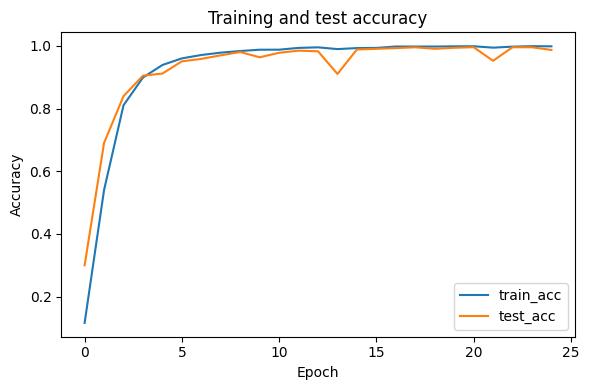

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_acc"], label="train_acc")
plt.plot(history["test_acc"], label="test_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and test accuracy")
plt.legend()
plt.tight_layout()
# plt.savefig(output_dir / "04_accuracy_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()


In [ ]:
torch.save(asl_model, 'asl_model.pth')

NameError: name 'lis_model' is not defined

In [ ]:
import pickle
with open('lis_model.pkl', 'wb') as outp:
    pickle.dump(lis_model, outp, pickle.HIGHEST_PROTOCOL)

NameError: name 'lis_model' is not defined

In [ ]:
#lis_classes = lis_train.label_to_idx
from model import SignLanguageCNN

lis_model = SignLanguageCNN(len(lis_classes))
lis_model = torch.load('lis_model.pth', weights_only=False)
lis_model.eval()

from camera import Camera


cam = Camera(lis_model, lis_classes)
cam.start()

I0000 00:00:1782834039.886602 5923666 init-domain.cc:128] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
I0000 00:00:1782834039.974190 5923666 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1782834039.983160 5923672 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782834039.993742 5923669 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782834040.043522 5923670 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x129600 and 16384x256)

: 